# Dar_015 — NASA battery reference experiments

**Questions:** How do measured capacity, full-record discharge energy and temperature vary within each reference cell history? Which protocol/quality fields must accompany a future power-model calibration?

R01 contains historical **Earth laboratory** experiments, not lunar environmental measurements or our selected hardware. All downloaded nested packages are inspected without extracting into the raw data folder. [Methods and algorithm implications](../EDA_Results.md).

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT/'darrel stuff/EDA'),str(ROOT)]
DATA=ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from environment_workflow import LocalRun as Run
from research_p1_readers import pin_source
import research_p1_readers
import reference_eda
from reference_eda import iter_battery_cells,battery_record_summary,relative_capacity,soil_table

def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def savefindings(run,values):
    run.path('findings.json').write_text(json.dumps(values,indent=2,default=str),encoding='utf-8');display(values)


## Design and safeguards
- Match every cell to its archive README; retain protocol, cutoff and recorded ambient temperature. Repeated MAT histories must be SHA-identical before deduplication; conflicting histories fail.
- Discharge index and source record index are distinct. Cycles from one battery are not independent replicate batteries.
- Integrate `max(-Current_measured,0)` and its product with measured voltage using seconds/3600. Only adjacent finite increasing-time endpoints contribute; NaNs are not bridged. Temperature completeness is audited separately. The trapezoid is an approximation between samples, not a new observation.
- Full-record integrals include recorded tails/rest/noise; source capacity can use a different cutoff definition. Differences are diagnostics, not automatic failures.
- Relative capacity uses that cell's first positive reported capacity, not an assumed universal rating or a mission state of health. Start-date vectors have no asserted UTC timezone.
- Predeclare B0005 first/middle/last discharge for trace illustrations. No cohort deletion, causal temperature derating, learned mission limits, or EIS frequency fit.
- Complex-valued source Re/Rct fit estimates are retained as real/imaginary components and flagged; they are not converted to a magnitude or silently used as real resistance. Empty capacity arrays remain missing, distinct from recorded zero capacity.

B0005 616 operation records


B0006 616 operation records


B0007 616 operation records
B0018 319 operation records


B0025 80 operation records
B0026 80 operation records
B0027 80 operation records
B0028 80 operation records


B0029 97 operation records
B0030 97 operation records
B0031 97 operation records
B0032 97 operation records


B0033 486 operation records
B0034 486 operation records


... (4 outputs left out)

B0047 184 operation records
B0048 184 operation records
B0049 62 operation records
B0050 62 operation records
B0051 62 operation records


B0052 62 operation records
B0053 137 operation records


B0054 253 operation records
B0055 252 operation records


B0056 252 operation records


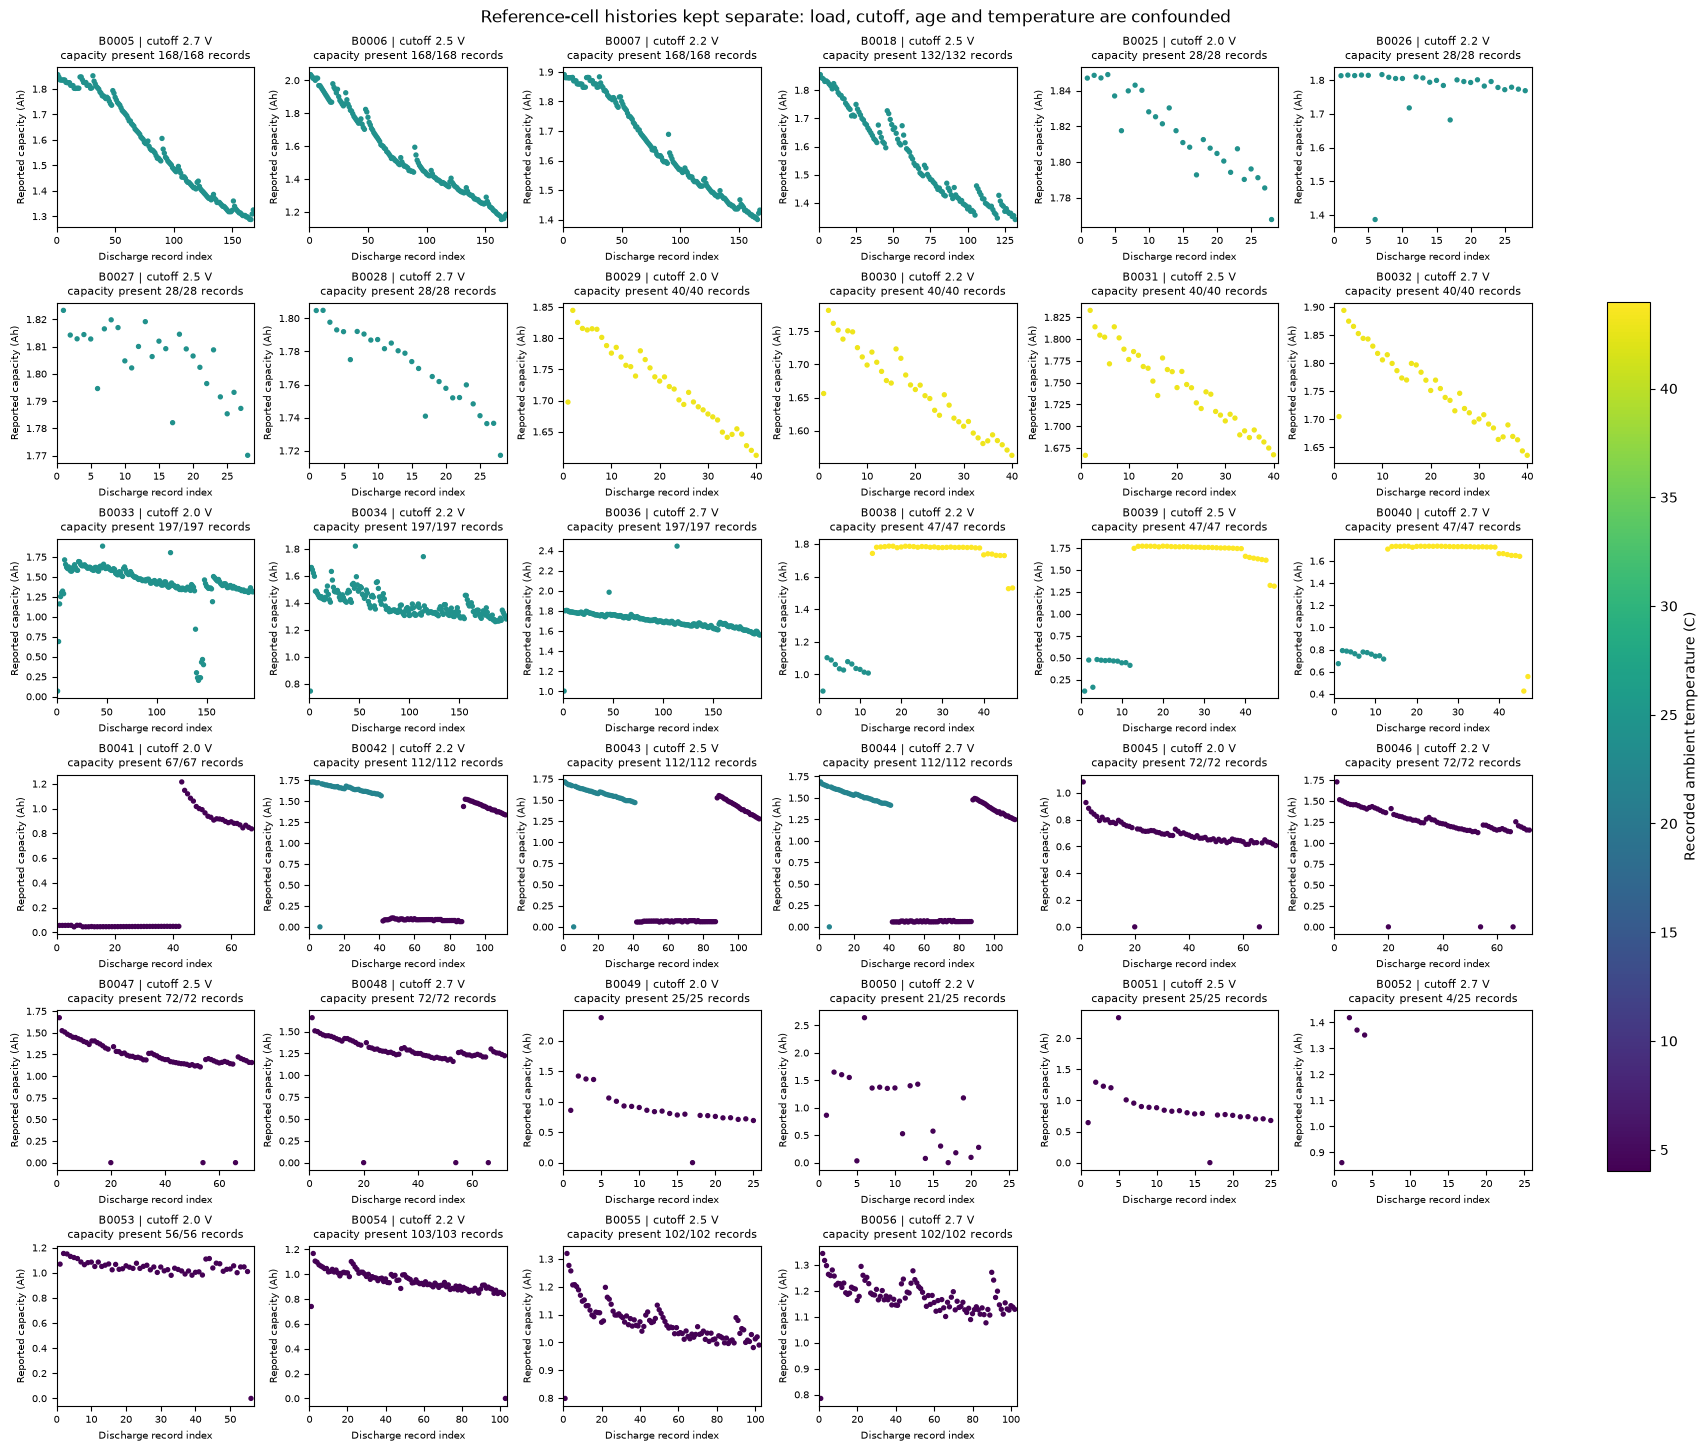

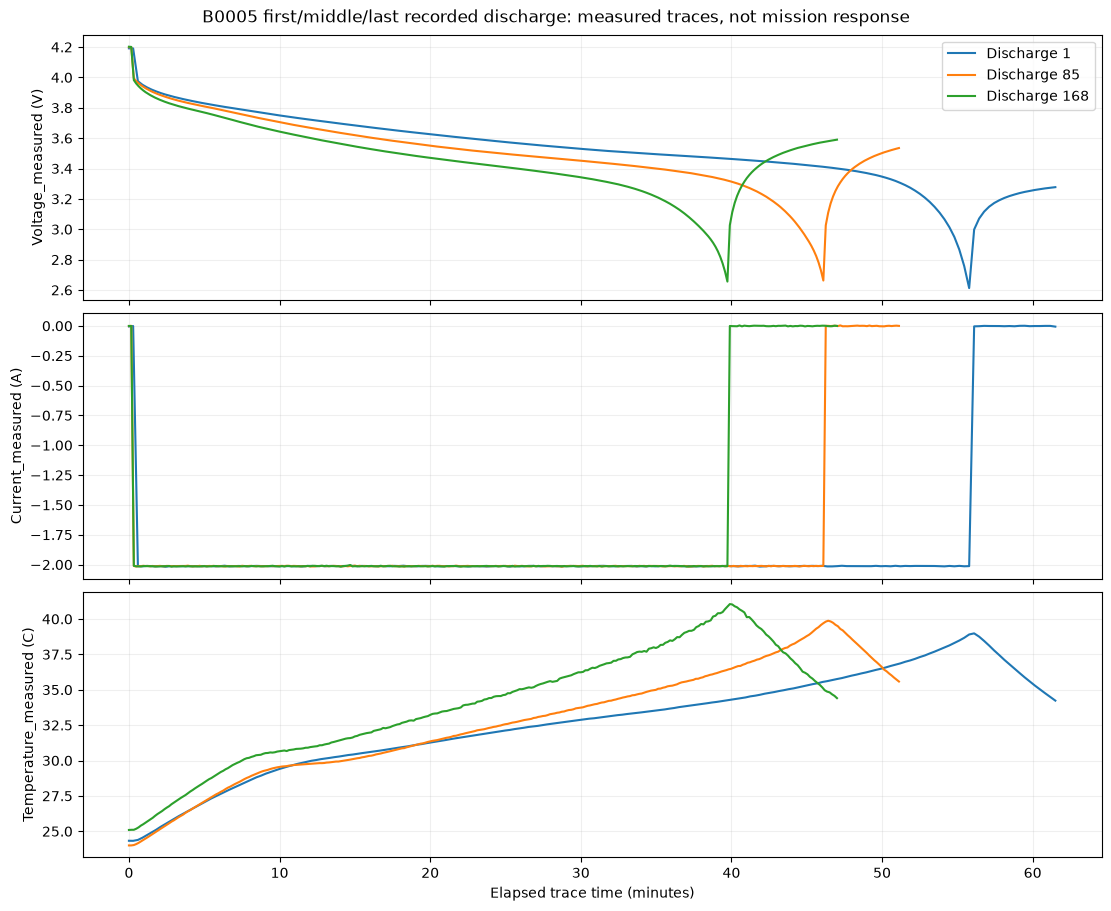

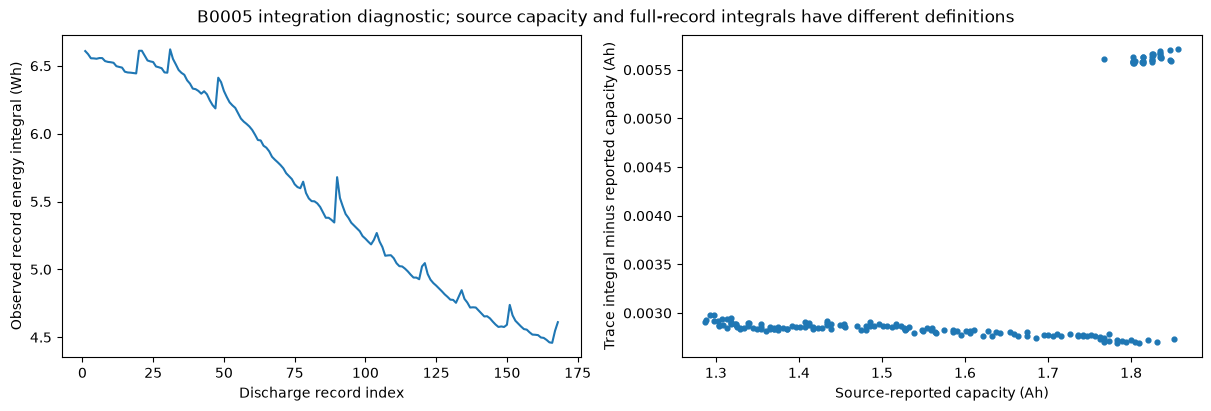

{'unique_cells': 34,
 'mat_members_seen': 38,
 'duplicate_mat_members': 4,
 'protocol_documents': 9,
 'operation_records': 7565,
 'operation_counts': {'charge': 2815, 'discharge': 2794, 'impedance': 1956},
 'discharge_records': 2794,
 'discharge_trace_status': {'all_intervals': 2794},
 'recorded_ambient_values_C': [4.0, 22.0, 24.0, 43.0, 44.0],
 'reported_capacity_missing': 25,
 'complex_Re_records': 9,
 'complex_Rct_records': 9,
 'nonpositive_reported_capacity_records': 19,
 'example': {'cell': 'B0005',
  'discharges': 168,
  'first_reported_capacity_Ah': np.float64(1.8564874208181574),
  'last_reported_capacity_Ah': np.float64(1.3250793286429356),
  'first_observed_energy_Wh': np.float64(6.608760662182745),
  'last_observed_energy_Wh': np.float64(4.611047446323755)},
 'mission_equipment_checks': 'Unknown',
 'limits': ['Repeated cell cycles are not independent batteries',
  'Cutoff/load/temperature/age effects are not isolated',
  'Trapezoidal integrals assume linear change between va

,cell_id,protocol_id,discharge_records,ambient_values_C,documented_stop_voltage_V,positive_reported_capacity_records,first_reported_capacity_Ah,last_reported_capacity_Ah,reported_capacity_min_Ah,reported_capacity_max_Ah,first_observed_energy_Wh,last_observed_energy_Wh,last_to_first_reported_capacity_ratio,peak_recorded_temperature_C,complete_trace_records
0,B0005,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,168,24.0,2.7,168,1.856487,1.325079,1.287453,1.856487,6.608761,4.611047,0.713756,41.450232,168
1,B0006,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,168,24.0,2.5,168,2.035338,1.185675,1.153818,2.035338,7.259524,4.053046,0.582545,42.007540,168
2,B0007,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,168,24.0,2.2,168,1.891052,1.432455,1.400455,1.891052,6.789420,5.076853,0.757491,42.332522,168
3,B0018,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,132,24.0,2.5,132,1.855005,1.341051,1.341051,1.855005,6.605907,4.700705,0.722937,38.878688,132
4,B0025,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,28,24.0,2.0,28,1.847011,1.767789,1.767789,1.848984,6.276491,5.986494,0.957108,41.829088,28
5,B0026,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,28,24.0,2.2,28,1.813250,1.768754,1.386337,1.816528,6.141567,5.977625,0.975460,40.904071,28
6,B0027,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,28,24.0,2.5,28,1.823308,1.770093,1.770093,1.823308,5.985056,5.698937,0.970814,43.208685,28
7,B0028,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,28,24.0,2.7,28,1.804685,1.717234,1.717234,1.804783,6.427243,6.124272,0.951542,32.506080,28
8,B0029,5e823bab7fc6106520f4f7ddbae9d44362451fe49fc410...,40,43.0,2.0,40,1.697507,1.612080,1.612080,1.844701,5.848769,5.594337,0.949675,60.332434,40
9,B0030,5e823bab7fc6106520f4f7ddbae9d44362451fe49fc410...,40,43.0,2.2,40,1.656071,1.562780,1.562780,1.781555,5.696259,5.378481,0.943668,63.024216,40


,mode,integration_status,records
0,charge,all_intervals,2790
1,charge,partial_observed_intervals,25
2,discharge,all_intervals,2794
3,impedance,not_time_series,1956


,cell_id,protocol_id,ambient_temperature_C,documented_stop_voltage_V,records,median_observed_energy_Wh,minimum_observed_energy_Wh,maximum_observed_energy_Wh,median_reported_capacity_Ah,median_peak_temperature_C
0,B0005,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,24.0,2.7,168,5.493862,4.458846,6.621414,1.557085,40.080753
1,B0006,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,24.0,2.5,168,5.158911,3.924367,7.259524,1.485372,40.333019
2,B0007,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,24.0,2.2,168,5.776041,4.944151,6.789420,1.616125,40.607821
3,B0018,9d7b701ed52fe453b7257338f250d5fb767b991f8d1bee...,24.0,2.5,132,5.432493,4.700705,6.605907,1.531892,37.750585
4,B0025,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,24.0,2.0,28,6.178730,5.986494,6.292192,1.815056,41.187051
5,B0026,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,24.0,2.2,28,6.099551,4.616581,6.160304,1.797639,40.561979
6,B0027,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,24.0,2.5,28,5.839110,5.698937,5.985056,1.808979,42.658855
7,B0028,84f9998ecd67cf3214123bcbd6b2a9d983f2dd7711f96b...,24.0,2.7,28,6.329768,6.124272,6.431487,1.774432,31.762320
8,B0029,5e823bab7fc6106520f4f7ddbae9d44362451fe49fc410...,43.0,2.0,40,5.998830,5.594337,6.410067,1.726824,59.987457
9,B0030,5e823bab7fc6106520f4f7ddbae9d44362451fe49fc410...,43.0,2.2,40,5.735154,5.378481,6.144050,1.659070,62.515194


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_015_battery_reference\20261106T160105346409Z_3ad1ca


In [2]:
CELL_LIMIT=None  # Use 1 for a representative first execution; None covers every unique history.
EXAMPLE_CELL='B0005'
archives=list((DATA/'reference/battery_tests').rglob('*.zip'))
if len(archives)!=1:raise ValueError('Expected one downloaded R01 outer ZIP, not partials or extracted substitutes')
with Run(ROOT,'analysis/dar_015_battery_reference',{'dataset':'R01','cell_limit':CELL_LIMIT,
    'scope':'all unique cell histories in local package; exact SHA-identical re-packaging deduplicated',
    'integration':'trapezoidal max(-I,0) and V*max(-I,0) over finite adjacent increasing-time samples',
    'example_cell':EXAMPLE_CELL,'mission_equipment_claim':False},'Earth/Dar_015_battery_reference_experiments.ipynb') as run:
    run.input(Path(reference_eda.__file__));run.input(Path(research_p1_readers.__file__))
    archive=pin_source(run,archives[0])
    inventory,documents,frames,examples=[],{},[],[]
    for info,records in iter_battery_cells(archive,inventory,documents,CELL_LIMIT):
        frame=battery_record_summary(info,records);frames.append(frame)
        print(info['cell_id'],len(frame),'operation records')
        if info['cell_id']==EXAMPLE_CELL:
            selected=[(i+1,r) for i,r in enumerate(records) if r['type']=='discharge']
            if not selected:raise ValueError('Declared example cell has no discharges')
            positions=sorted(set([0,len(selected)//2,len(selected)-1]))
            for position in positions:
                index,record=selected[position];d=record['data']
                vectors={k:np.asarray(d[k],dtype=float).reshape(-1) for k in ['Time','Voltage_measured','Current_measured','Temperature_measured']}
                if len({len(a) for a in vectors.values()})!=1:raise ValueError('Example trace has mismatched source vectors')
                example=pd.DataFrame(vectors);example['record_index']=index;example['discharge_index']=position+1
                example['cell_id']=EXAMPLE_CELL;examples.append(example)
        del records,frame
    if not frames:raise ValueError('No battery histories decoded')
    records=pd.concat(frames,ignore_index=True)
    if records.duplicated(['cell_id','record_index']).any():raise ValueError('Repeated source record after deduplication')
    records.to_csv(run.path('operation_records.csv.gz'),index=False,compression={'method':'gzip','mtime':0})
    members=pd.DataFrame(inventory);members.to_csv(run.path('package_member_inventory.csv'),index=False)
    protocol_rows=[]
    for key,doc in documents.items():
        run.path('protocols/'+key+'.txt').write_text(doc['text'],encoding='utf-8')
        protocol_rows.append({'protocol_id':key,'description':doc['protocol_description']})
    pd.DataFrame(protocol_rows).to_csv(run.path('protocol_register.csv'),index=False)
    discharge=relative_capacity(records.loc[records['mode'].eq('discharge')])
    discharge['integrated_minus_reported_capacity_Ah']=discharge.observed_discharge_Ah-discharge.reported_capacity_Ah
    discharge['temperature_above_recorded_ambient_C']=discharge.temperature_max_C-discharge.ambient_temperature_C
    discharge['evidence_type']='historical laboratory reference; not selected mission battery'
    discharge.to_csv(run.path('discharge_features.csv'),index=False)
    summaries=[]
    for cell,part in discharge.groupby('cell_id',sort=True):
        part=part.sort_values('record_index');first,last=part.iloc[0],part.iloc[-1]
        summaries.append({'cell_id':cell,'protocol_id':first.protocol_id,'discharge_records':len(part),
            'ambient_values_C':';'.join(str(v) for v in sorted(part.ambient_temperature_C.dropna().unique())),
            'documented_stop_voltage_V':first.documented_stop_voltage_V,
            'positive_reported_capacity_records':int(part.reported_capacity_Ah.gt(0).sum()),
            'first_reported_capacity_Ah':first.reported_capacity_Ah,'last_reported_capacity_Ah':last.reported_capacity_Ah,
            'reported_capacity_min_Ah':part.reported_capacity_Ah.min(),'reported_capacity_max_Ah':part.reported_capacity_Ah.max(),
            'first_observed_energy_Wh':first.observed_discharge_Wh,'last_observed_energy_Wh':last.observed_discharge_Wh,
            'last_to_first_reported_capacity_ratio':last.reported_capacity_Ah/first.reported_capacity_Ah if first.reported_capacity_Ah>0 else np.nan,
            'peak_recorded_temperature_C':part.temperature_max_C.max(),
            'complete_trace_records':int(part.integration_status.eq('all_intervals').sum())})
    cells=pd.DataFrame(summaries);cells.to_csv(run.path('cell_summary.csv'),index=False)
    ambient=discharge.groupby(['cell_id','protocol_id','ambient_temperature_C','documented_stop_voltage_V'],dropna=False).agg(
        records=('record_index','size'),median_observed_energy_Wh=('observed_discharge_Wh','median'),
        minimum_observed_energy_Wh=('observed_discharge_Wh','min'),maximum_observed_energy_Wh=('observed_discharge_Wh','max'),
        median_reported_capacity_Ah=('reported_capacity_Ah','median'),median_peak_temperature_C=('temperature_max_C','median')).reset_index()
    ambient.to_csv(run.path('cell_ambient_condition_summary.csv'),index=False)
    quality=records.groupby(['mode','integration_status'],dropna=False).size().rename('records').reset_index()
    quality.to_csv(run.path('operation_quality_summary.csv'),index=False)
    impedance=records.loc[records['mode'].eq('impedance')]
    impedance.groupby(['cell_id','ambient_temperature_C'],dropna=False).agg(records=('record_index','size'),
        Re_finite=('Re_ohm','count'),Rct_finite=('Rct_ohm','count'),Re_complex=('Re_estimate_status',lambda x:x.eq('complex_estimate').sum()),Rct_complex=('Rct_estimate_status',lambda x:x.eq('complex_estimate').sum()),Re_median_ohm=('Re_ohm','median'),
        Rct_median_ohm=('Rct_ohm','median')).to_csv(run.path('impedance_parameter_summary.csv'))
    fig,axes=plt.subplots(int(np.ceil(len(cells)/6)),6,figsize=(17,max(3,int(np.ceil(len(cells)/6))*2.4)),squeeze=False,layout='constrained')
    finite_ambient=discharge.ambient_temperature_C.dropna()
    vmin,vmax=finite_ambient.min(),finite_ambient.max()
    scatter=None
    for ax,(cell,part) in zip(axes.flat,discharge.groupby('cell_id',sort=True)):
        scatter=ax.scatter(part.discharge_index,part.reported_capacity_Ah,c=part.ambient_temperature_C,cmap='viridis',vmin=vmin,vmax=vmax,s=8)
        ax.set_title(cell+' | cutoff '+str(part.documented_stop_voltage_V.iloc[0])+' V\ncapacity present '+str(part.reported_capacity_Ah.notna().sum())+'/'+str(len(part))+' records',fontsize=8)
        ax.set_xlim(0,part.discharge_index.max()+1)
        ax.set_xlabel('Discharge record index',fontsize=7);ax.set_ylabel('Reported capacity (Ah)',fontsize=7);ax.tick_params(labelsize=7)
    for ax in list(axes.flat)[len(cells):]:ax.set_visible(False)
    fig.colorbar(scatter,ax=list(axes.flat),label='Recorded ambient temperature (C)',shrink=.65)
    fig.suptitle('Reference-cell histories kept separate: load, cutoff, age and temperature are confounded',fontsize=12)
    savefig(run,fig,'cell_capacity_histories')
    if not examples:raise ValueError('Declared example cell absent from this selection')
    examples=pd.concat(examples,ignore_index=True);examples.to_csv(run.path('declared_example_traces.csv'),index=False)
    fig,axes=plt.subplots(3,1,figsize=(11,9),sharex=True,layout='constrained')
    for index,part in examples.groupby('discharge_index'):
        for ax,variable,unit in zip(axes,['Voltage_measured','Current_measured','Temperature_measured'],['V','A','C']):
            ax.plot(part.Time/60,part[variable],label=f'Discharge {index}');ax.set_ylabel(variable+' ('+unit+')');ax.grid(alpha=.2)
    axes[0].legend();axes[-1].set_xlabel('Elapsed trace time (minutes)')
    fig.suptitle(EXAMPLE_CELL+' first/middle/last recorded discharge: measured traces, not mission response')
    savefig(run,fig,'declared_cell_discharge_traces')
    selected=discharge.loc[discharge.cell_id.eq(EXAMPLE_CELL)]
    fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
    axes[0].plot(selected.discharge_index,selected.observed_discharge_Wh);axes[0].set(xlabel='Discharge record index',ylabel='Observed record energy integral (Wh)')
    axes[1].scatter(selected.reported_capacity_Ah,selected.integrated_minus_reported_capacity_Ah,s=12)
    axes[1].set(xlabel='Source-reported capacity (Ah)',ylabel='Trace integral minus reported capacity (Ah)')
    fig.suptitle(EXAMPLE_CELL+' integration diagnostic; source capacity and full-record integrals have different definitions')
    savefig(run,fig,'energy_capacity_diagnostics')
    first,last=selected.iloc[0],selected.iloc[-1]
    status={'scope':'laboratory reference only','mission_battery_selected':False,'mission_usable_capacity_Wh':None,
            'operational_constraint_status':'Unknown','implementation':'conditional per-cell/protocol/ambient/age feature lookup; validate transfer before use',
            'exclusions':['No vacuum/polar extrapolation','No universal temperature derating fit','No automatic mission power margin',
                          'No Nyquist-frequency interpretation: frequency vectors are absent from these records']}
    run.path('algorithm_handoff.json').write_text(json.dumps(status,indent=2),encoding='utf-8')
    savefindings(run,{'unique_cells':int(records.cell_id.nunique()),'mat_members_seen':len(members),
        'duplicate_mat_members':int(members.duplicate_history.sum()),'protocol_documents':len(documents),
        'operation_records':len(records),'operation_counts':records['mode'].value_counts().to_dict(),
        'discharge_records':len(discharge),'discharge_trace_status':discharge.integration_status.value_counts().to_dict(),
        'recorded_ambient_values_C':sorted(records.ambient_temperature_C.dropna().unique().tolist()),
        'reported_capacity_missing':int(discharge.reported_capacity_Ah.isna().sum()),
        'complex_Re_records':int(impedance.Re_estimate_status.eq('complex_estimate').sum()),
        'complex_Rct_records':int(impedance.Rct_estimate_status.eq('complex_estimate').sum()),
        'nonpositive_reported_capacity_records':int(discharge.reported_capacity_Ah.le(0).sum()),
        'example':{'cell':EXAMPLE_CELL,'discharges':len(selected),'first_reported_capacity_Ah':first.reported_capacity_Ah,
            'last_reported_capacity_Ah':last.reported_capacity_Ah,'first_observed_energy_Wh':first.observed_discharge_Wh,
            'last_observed_energy_Wh':last.observed_discharge_Wh},'mission_equipment_checks':'Unknown',
        'limits':['Repeated cell cycles are not independent batteries','Cutoff/load/temperature/age effects are not isolated',
                  'Trapezoidal integrals assume linear change between valid adjacent samples; no missing-interval interpolation',
                  'Low-capacity or unusual source records are retained, not silently deleted']})
    display(cells);display(quality);display(ambient)
OUT=run.directory;print('Completed:',OUT)


## Implementation handoff
Use the exported **cell/protocol/ambient/age-qualified measured feature table** to test a battery energy integrator or develop a conditional reference lookup. Validate any interpolation within a matched experimental domain and hold out whole cells for transfer claims. Loads, selected battery, solar-array model, mission dates, initial state and reserves still need explicit inputs. No public experiment becomes our flight qualification or a Stage 3 pass. Authenticated sources remain KIV.